# ホテル予約キャンセル予測：SHAPによるモデル解釈

このNotebookでは、`02_Cancellation_Prediction.ipynb`で採用したRandom Forestが、どの特徴量を重視してキャンセル確率を計算しているかをSHAPで確認する。

02で実施したモデル比較、閾値調整、Final Test評価は繰り返さない。一方、このNotebookだけでも再現できるように、同じデータ分割・特徴量・前処理を使って、**Trainのみ**でSHAP分析用モデルを再学習する。02のFinal Test用モデルはTrain＋Validationで学習しているため、ここで説明するモデルとは学習範囲が異なる。


## 1. SHAP分析の目的

Random Forestは複雑な関係を学習できる一方、予測の根拠をそのまま読み取りにくい。そこでSHAPを使い、キャンセルクラス（`is_canceled=1`）について次の点を確認する。

- モデル全体で重要だった特徴量
- 特徴量の値がキャンセル予測を押し上げたか、押し下げたか
- 高リスクと予測された1件で、どの特徴量が判断に寄与したか

SHAP値はモデルの予測への寄与を表すものであり、キャンセルの原因や因果関係を証明するものではない。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.validation import check_is_fitted
from scipy import sparse
import shap


sns.set_theme(style="whitegrid", context="notebook")
COLORS = {
    "primary": "#2F6690",
    "secondary": "#F28E2B",
    "accent": "#59A14F",
    "danger": "#E15759",
    "neutral": "#9D9D9D",
}
pd.set_option("display.max_columns", 50)

# notebooks/からの実行と、リポジトリ直下からの実行の両方に対応する
data_candidates = [
    Path("../data/hotel_bookings.csv"),
    Path("data/hotel_bookings.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "hotel_bookings.csvが見つかりません。READMEの手順に従いdata/へ配置してください。"
    )


## 2. データ・モデルの準備

02と同じ読み込みパスと特徴量方針を使用する。予測時点は予約登録直後とし、予約後に確定する情報や、登録時点で利用可能か不明な特徴量は除外する。`country`と`agent`は数値の大小ではなくカテゴリとして扱う。


In [2]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={" ": "hotel"})

TARGET = "is_canceled"
COUNTRY = "country"

POST_BOOKING_COLUMNS = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
]

# 予約登録時点の値である保証がないため保守的に除外する
UNCERTAIN_AT_REGISTRATION_COLUMNS = [
    "deposit_type",
    "adr",
    "total_of_special_requests",
]

NOT_USED_COLUMNS = ["agent", "company"]

excluded_columns = set(
    [TARGET, COUNTRY]
    + POST_BOOKING_COLUMNS
    + UNCERTAIN_AT_REGISTRATION_COLUMNS
    + NOT_USED_COLUMNS
)

baseline_feature_columns = [
    column for column in df.columns if column not in excluded_columns
]
country_feature_columns = baseline_feature_columns + [COUNTRY]
agent_feature_columns = country_feature_columns + ["agent"]

feature_policy = pd.DataFrame({
    "Category": [
        "Common features",
        "Added in country experiment",
        "Added in agent experiment",
        "Excluded after booking / target leakage risk",
        "Excluded conservatively",
        "Not used",
    ],
    "Columns": [
        ", ".join(baseline_feature_columns),
        COUNTRY,
        "agent",
        ", ".join(POST_BOOKING_COLUMNS),
        ", ".join(UNCERTAIN_AT_REGISTRATION_COLUMNS),
        "company",
    ],
})

print("データ件数・列数:", df.shape)
print("共通特徴量数:", len(baseline_feature_columns))
print("最終候補のraw特徴量数:", len(agent_feature_columns))
display(feature_policy)


データ件数・列数: (119390, 32)
共通特徴量数: 20
最終候補のraw特徴量数: 22


,Category,Columns
0,Common features,"hotel, lead_time, arrival_date_year, arrival_d..."
1,Added in country experiment,country
2,Added in agent experiment,agent
3,Excluded after booking / target leakage risk,"reservation_status, reservation_status_date, a..."
4,Excluded conservatively,"deposit_type, adr, total_of_special_requests"
5,Not used,company


In [3]:
class TopCountryGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位Nか国を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=17):
        self.top_n = top_n

    @staticmethod
    def _to_series(X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.fillna("Unknown").astype(str)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_countries_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_countries_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_countries_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["country"], dtype=object)


class TopAgentGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位N代理店を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=10):
        self.top_n = top_n

    @staticmethod
    def _normalize_value(value):
        if pd.isna(value):
            return "Unknown"

        # 9.0と9を同じカテゴリ"9"として扱う
        if isinstance(value, (int, float, np.integer, np.floating)):
            numeric_value = float(value)
            if np.isfinite(numeric_value) and numeric_value.is_integer():
                return str(int(numeric_value))
            return format(numeric_value, "g")

        return str(value).strip()

    @classmethod
    def _to_series(cls, X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.map(cls._normalize_value)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_agents_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_agents_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_agents_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["agent"], dtype=object)


### 2.1 時系列分割とデータリーク対策

02と同様に、到着日から`lead_time`を引いた推定予約日でTrain 60%・Validation 20%・Final Test 20%に分割する。上位国・上位代理店の選定、欠損値補完、One-Hot EncodingはPipeline内でTrainだけにfitする。

Final Testのindexは分割の再現と重複グループ確認のために作成するが、SHAPサンプルの抽出、モデル学習、予測、結果の解釈には使用しない。


In [4]:
arrival_month_number = pd.to_datetime(
    df["arrival_date_month"], format="%B"
).dt.month
arrival_date = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": arrival_month_number,
    "day": df["arrival_date_day_of_month"],
})
estimated_booking_date = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")

train_cutoff = estimated_booking_date.quantile(0.60, interpolation="lower")
validation_cutoff = estimated_booking_date.quantile(0.80, interpolation="lower")

train_index = df.index[estimated_booking_date <= train_cutoff]
validation_index = df.index[
    (estimated_booking_date > train_cutoff)
    & (estimated_booking_date <= validation_cutoff)
]
final_test_index = df.index[estimated_booking_date > validation_cutoff]

duplicate_group_columns = [
    column
    for column in df.columns
    if column not in [TARGET, "reservation_status", "reservation_status_date"]
]
duplicate_group_id = pd.util.hash_pandas_object(
    df[duplicate_group_columns], index=False
)
train_groups = set(duplicate_group_id.loc[train_index])
validation_groups = set(duplicate_group_id.loc[validation_index])
final_test_groups = set(duplicate_group_id.loc[final_test_index])

assert train_groups.isdisjoint(validation_groups)
assert train_groups.isdisjoint(final_test_groups)
assert validation_groups.isdisjoint(final_test_groups)

split_summary = pd.DataFrame({
    "Rows": [len(train_index), len(validation_index), len(final_test_index)],
    "Start": [
        estimated_booking_date.loc[train_index].min(),
        estimated_booking_date.loc[validation_index].min(),
        estimated_booking_date.loc[final_test_index].min(),
    ],
    "End": [
        estimated_booking_date.loc[train_index].max(),
        estimated_booking_date.loc[validation_index].max(),
        estimated_booking_date.loc[final_test_index].max(),
    ],
    # Final Testの目的変数分布はモデル・閾値確定前に見ない
    "Cancellation_Rate": [
        df.loc[train_index, TARGET].mean(),
        df.loc[validation_index, TARGET].mean(),
        np.nan,
    ],
}, index=["Train", "Validation", "Final Test"])

display(split_summary.style.format({"Cancellation_Rate": "{:.1%}"}))
print("完全重複行数:", int(df.duplicated().sum()))
print("重複グループの分割またぎ: 0")


,Rows,Start,End,Cancellation_Rate
Train,71688,2013-06-24 00:00:00,2016-08-17 00:00:00,38.8%
Validation,23999,2016-08-18 00:00:00,2017-01-12 00:00:00,37.3%
Final Test,23703,2017-01-13 00:00:00,2017-08-31 00:00:00,nan%


完全重複行数: 31994
重複グループの分割またぎ: 0


In [5]:
# 数値・カテゴリ列はTrainの型情報だけから確定する
train_baseline_data = df.loc[train_index, baseline_feature_columns]
numeric_columns = train_baseline_data.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = train_baseline_data.select_dtypes(exclude=["number"]).columns.tolist()


def build_random_forest_pipeline(
    include_country,
    agent_top_n,
    model_params,
):
    """既存の前処理条件を共通化したRandom Forest Pipelineを作る。"""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    transformers = [
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ]

    if include_country:
        country_pipeline = Pipeline([
            ("group", TopCountryGrouper(top_n=17)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("country", country_pipeline, [COUNTRY]))

    if agent_top_n is not None:
        agent_pipeline = Pipeline([
            ("group", TopAgentGrouper(top_n=agent_top_n)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("agent", agent_pipeline, ["agent"]))

    preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(**model_params)),
    ])


### 2.2 02で採用した設定による再学習

SHAP分析用モデルは、02で選ばれた特徴量とRandom Forestの設定を固定し、Trainのみで学習する。判定閾値は02と同じ0.30だが、閾値は予測クラスの表示にだけ使い、SHAP値の計算方法には影響しない。


In [6]:
# 02で採用した最終設定を固定する
FINAL_MODEL_PARAMS = {
    "n_estimators": 200,
    "max_depth": 18,
    "min_samples_leaf": 4,
    "min_samples_split": 8,
    "random_state": 42,
    "n_jobs": -1,
}
FINAL_THRESHOLD = 0.30

X_train_shap = df.loc[train_index, agent_feature_columns]
y_train_shap = df.loc[train_index, TARGET]

# country上位17か国・agent上位10社をTrain内で選定して学習する
shap_pipeline = build_random_forest_pipeline(
    include_country=True,
    agent_top_n=10,
    model_params=FINAL_MODEL_PARAMS,
)
shap_pipeline.fit(X_train_shap, y_train_shap)

shap_preprocessor = shap_pipeline.named_steps["preprocess"]
shap_random_forest = shap_pipeline.named_steps["model"]

top_countries = (
    shap_preprocessor.named_transformers_["country"]
    .named_steps["group"]
    .top_countries_
)
top_agents = (
    shap_preprocessor.named_transformers_["agent"]
    .named_steps["group"]
    .top_agents_
)

print("学習データ件数:", len(X_train_shap))
print("Random Forest設定:", FINAL_MODEL_PARAMS)
print("判定閾値:", FINAL_THRESHOLD)
print("Trainから選定したcountry数:", len(top_countries))
print("Trainから選定したagent数:", len(top_agents))
print("Final Testは学習・予測・SHAP分析に使用していません。")


学習データ件数: 71688
Random Forest設定: {'n_estimators': 200, 'max_depth': 18, 'min_samples_leaf': 4, 'min_samples_split': 8, 'random_state': 42, 'n_jobs': -1}
判定閾値: 0.3
Trainから選定したcountry数: 17
Trainから選定したagent数: 10
Final Testは学習・予測・SHAP分析に使用していません。


### 2.3 ValidationからSHAPサンプルを抽出

計算量を抑えるため、Validationから`random_state=42`で最大600件を無作為抽出する。学習済みの前処理器を`transform`だけに使用し、One-Hot Encoding後の特徴量名を`ColumnTransformer`から取得する。


In [7]:
SHAP_RANDOM_STATE = 42
SHAP_SAMPLE_SIZE = 600

shap_sample_size = min(SHAP_SAMPLE_SIZE, len(validation_index))
shap_rng = np.random.default_rng(SHAP_RANDOM_STATE)
shap_sample_positions = np.sort(
    shap_rng.choice(len(validation_index), size=shap_sample_size, replace=False)
)
shap_validation_index = validation_index[shap_sample_positions]

X_shap_validation_raw = df.loc[shap_validation_index, agent_feature_columns]
y_shap_validation = df.loc[shap_validation_index, TARGET]

# Trainでfit済みの前処理だけをValidationへ適用する
X_shap_transformed = shap_preprocessor.transform(X_shap_validation_raw)
if sparse.issparse(X_shap_transformed):
    X_shap_matrix = X_shap_transformed.toarray()
else:
    X_shap_matrix = np.asarray(X_shap_transformed)

shap_feature_names_full = shap_preprocessor.get_feature_names_out().tolist()
shap_feature_names = [
    name.split("__", 1)[1] if "__" in name else name
    for name in shap_feature_names_full
]

if len(shap_feature_names) != X_shap_matrix.shape[1]:
    raise ValueError("変換後の列数と特徴量名の数が一致しません。")
if len(set(shap_feature_names)) != len(shap_feature_names):
    raise ValueError("One-Hot Encoding後の特徴量名に重複があります。")

X_shap_display = pd.DataFrame(
    X_shap_matrix,
    index=shap_validation_index,
    columns=shap_feature_names,
)

print("SHAPサンプル件数:", shap_sample_size)
print("One-Hot Encoding後の特徴量数:", len(shap_feature_names))


SHAPサンプル件数: 600
One-Hot Encoding後の特徴量数: 90


## 3. SHAP値の計算

`TreeExplainer`でキャンセルクラス（クラス1）のSHAP値を計算する。SHAPのバージョンによって戻り値がリスト・2次元配列・3次元配列になる違いを吸収し、Random Forestの`classes_`からクラス1の位置を確認して抽出する。

さらに、基準値と全SHAP値の合計を`predict_proba()`のキャンセル確率と比較し、SHAP値の出力単位と加法性を確認する。


In [8]:
def extract_class_shap_values(explainer, X, class_position, n_classes):
    """SHAPのバージョン差を吸収して指定クラスの値と基準値を返す。"""
    try:
        explanation = explainer(X, check_additivity=False)
        values_raw = explanation.values
        base_raw = explanation.base_values
    except (TypeError, AttributeError):
        values_raw = explainer.shap_values(X, check_additivity=False)
        base_raw = explainer.expected_value

    if isinstance(values_raw, list):
        class_values = np.asarray(values_raw[class_position])
    else:
        values_array = np.asarray(values_raw)
        if values_array.ndim == 3 and values_array.shape[2] == n_classes:
            class_values = values_array[:, :, class_position]
        elif values_array.ndim == 3 and values_array.shape[0] == n_classes:
            class_values = values_array[class_position]
        elif values_array.ndim == 2:
            class_values = values_array
        else:
            raise ValueError(f"未対応のSHAP値の形状です: {values_array.shape}")

    base_array = np.asarray(base_raw)
    n_samples = class_values.shape[0]
    if base_array.ndim == 0:
        class_base = np.repeat(float(base_array), n_samples)
    elif base_array.ndim == 1:
        if base_array.size == n_classes:
            class_base = np.repeat(base_array[class_position], n_samples)
        elif base_array.size == n_samples:
            class_base = base_array
        else:
            raise ValueError(f"未対応の基準値の形状です: {base_array.shape}")
    elif base_array.ndim == 2 and base_array.shape == (n_samples, n_classes):
        class_base = base_array[:, class_position]
    elif base_array.ndim == 2 and base_array.shape == (n_classes, n_samples):
        class_base = base_array[class_position]
    else:
        raise ValueError(f"未対応の基準値の形状です: {base_array.shape}")

    return np.asarray(class_values), np.asarray(class_base)


shap_explainer = shap.TreeExplainer(shap_random_forest)
class_labels = shap_random_forest.classes_.tolist()
if 1 not in class_labels:
    raise ValueError("学習済みモデルにキャンセルクラス1がありません。")
class_1_position = class_labels.index(1)

class_1_shap_values, class_1_base_values = extract_class_shap_values(
    shap_explainer,
    X_shap_matrix,
    class_position=class_1_position,
    n_classes=len(class_labels),
)

if class_1_shap_values.shape != X_shap_matrix.shape:
    raise ValueError(
        "クラス1のSHAP値と変換後データの形状が一致しません: "
        f"{class_1_shap_values.shape} / {X_shap_matrix.shape}"
    )

class_1_explanation = shap.Explanation(
    values=class_1_shap_values,
    base_values=class_1_base_values,
    data=X_shap_matrix,
    feature_names=shap_feature_names,
)

# SHAPの再構成値とRandom Forestのクラス1確率を比較する
shap_reconstructed_output = (
    class_1_base_values + class_1_shap_values.sum(axis=1)
)
shap_model_probability = shap_random_forest.predict_proba(X_shap_matrix)[
    :, class_1_position
]
shap_additivity_max_error = float(
    np.max(np.abs(shap_reconstructed_output - shap_model_probability))
)
shap_is_probability_unit = shap_additivity_max_error < 1e-6
shap_output_unit = (
    "キャンセル確率（predict_probaの確率単位）"
    if shap_is_probability_unit
    else "Random Forestのraw出力単位"
)
shap_output_unit_plot = (
    "cancellation probability"
    if shap_is_probability_unit
    else "raw Random Forest output"
)

print("クラスの並び:", class_labels)
print("分析対象クラス:", class_labels[class_1_position])
print("SHAP値の形状:", class_1_shap_values.shape)
print("SHAP値の単位:", shap_output_unit)
print(f"predict_probaとの最大再構成誤差: {shap_additivity_max_error:.10f}")
print("正のSHAP値はキャンセル予測を押し上げ、負の値は押し下げます。")


クラスの並び: [0, 1]
分析対象クラス: 1
SHAP値の形状: (600, 90)
SHAP値の単位: キャンセル確率（predict_probaの確率単位）
predict_probaとの最大再構成誤差: 0.0000000000
正のSHAP値はキャンセル予測を押し上げ、負の値は押し下げます。


## 4. SHAP Summary Plot

上位20列をBeeswarm Plotで表示する。横軸はキャンセルクラス1への寄与で、右側ほどキャンセル予測を押し上げ、左側ほど押し下げる。色は特徴量の値を表し、赤が高い値、青が低い値である。One-Hot列では、赤（1）がそのカテゴリに該当する予約を表す。


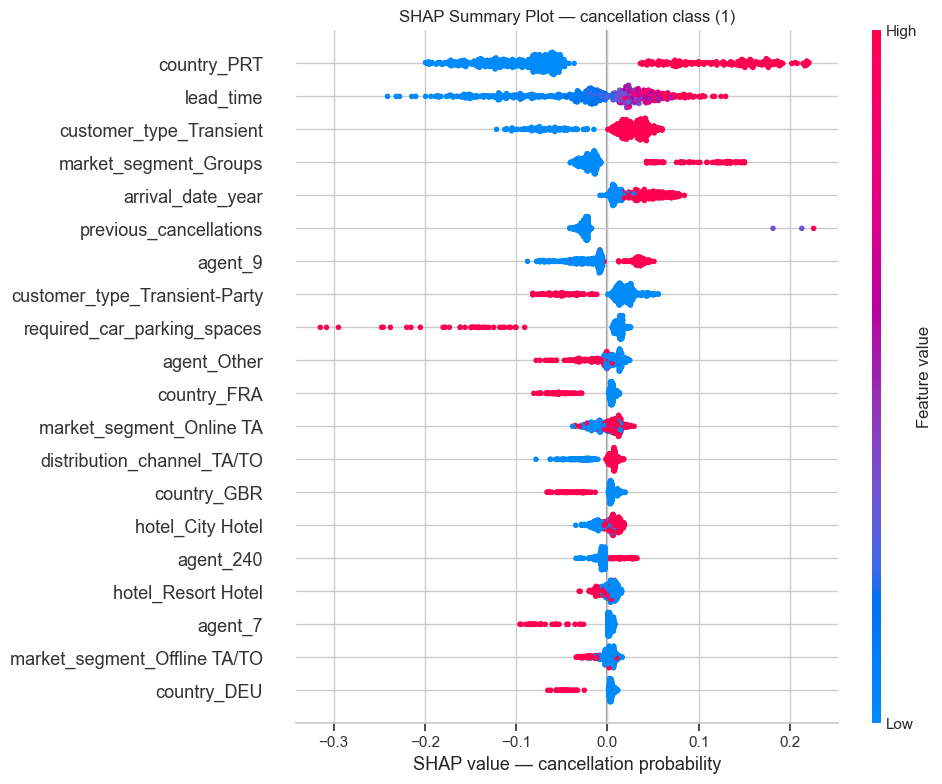

In [9]:
shap.summary_plot(
    class_1_shap_values,
    X_shap_display,
    max_display=20,
    plot_size=(10, 8),
    show=False,
)
plt.xlabel(f"SHAP value — {shap_output_unit_plot}")
plt.title("SHAP Summary Plot — cancellation class (1)")
plt.tight_layout()
plt.show()


## 5. 特徴量重要度の分析

`mean(|SHAP value|)`を使い、まずOne-Hot Encoding後の個別列を順位付けする。続いて、同じ元特徴量から展開された列を合計し、`country`や`agent`を元特徴量単位で比較する。

集約値はカテゴリ数の多さも反映するため、個別列ランキングとは意味が異なる。両方を分けて確認する。


,Feature,Original_Feature,Mean_Abs_SHAP
Rank,,,
1,country_PRT,country,0.108395
2,lead_time,lead_time,0.053869
3,customer_type_Transient,customer_type,0.034779
4,market_segment_Groups,market_segment,0.031984
5,arrival_date_year,arrival_date_year,0.031646
6,previous_cancellations,previous_cancellations,0.026653
7,agent_9,agent,0.026162
8,customer_type_Transient-Party,customer_type,0.024291
9,required_car_parking_spaces,required_car_parking_spaces,0.022186


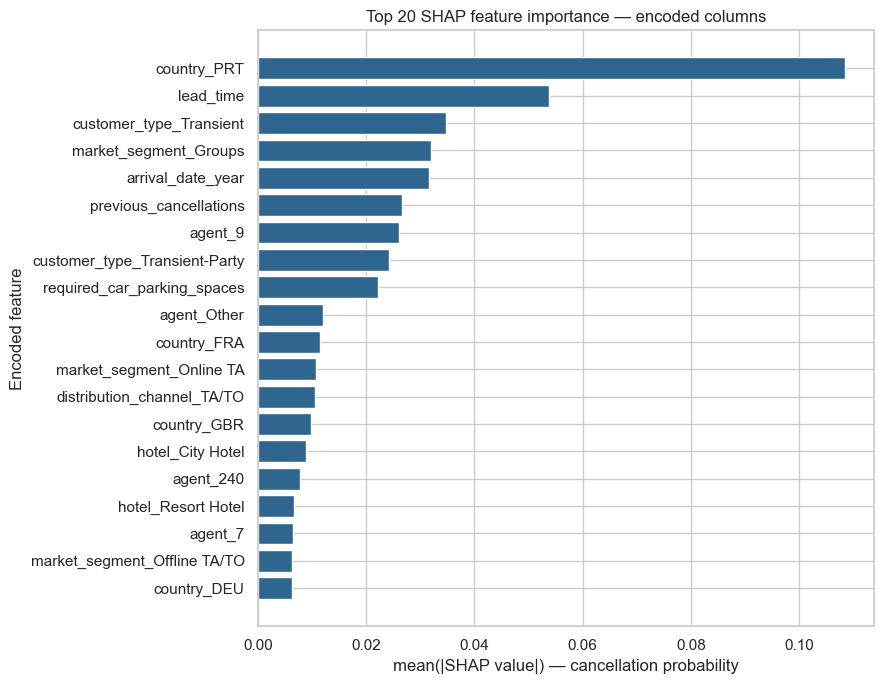

,Original_Feature,Mean_Abs_SHAP
Rank,,
1,country,0.147287
2,agent,0.066191
3,customer_type,0.060387
4,market_segment,0.055912
5,lead_time,0.053869
6,arrival_date_year,0.031646
7,previous_cancellations,0.026653
8,required_car_parking_spaces,0.022186
9,distribution_channel,0.017488


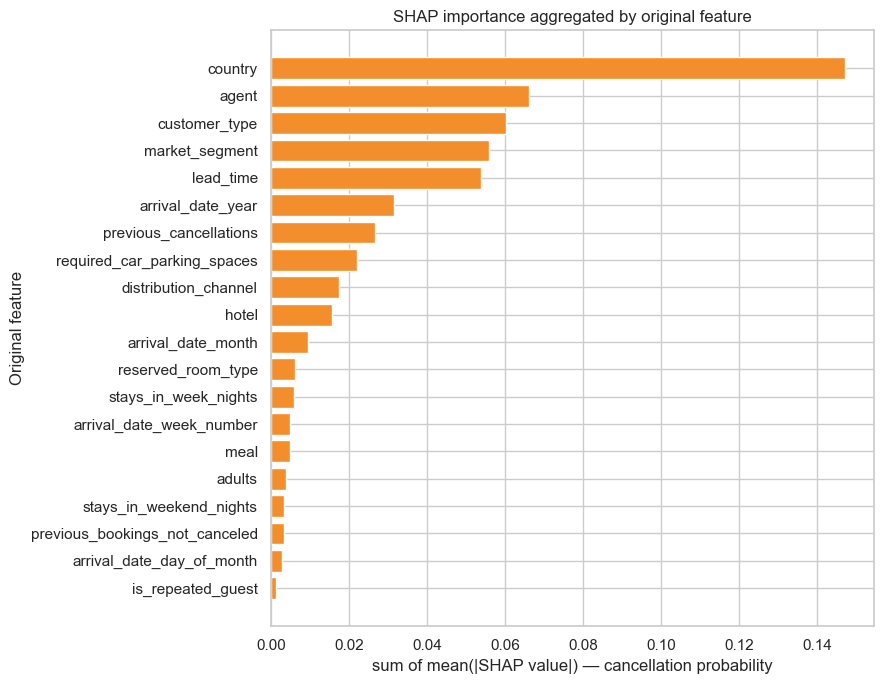

In [10]:
def build_original_feature_labels(preprocessor):
    """ColumnTransformerの出力位置から元特徴量名を対応付ける。"""
    labels = []
    for transformer_name, fitted_transformer, columns in preprocessor.transformers_:
        if transformer_name == "remainder" or transformer_name not in preprocessor.output_indices_:
            continue

        output_slice = preprocessor.output_indices_[transformer_name]
        output_count = output_slice.stop - output_slice.start

        if transformer_name == "numeric":
            transformer_labels = list(columns)
        elif transformer_name == "categorical":
            onehot = fitted_transformer.named_steps["onehot"]
            transformer_labels = [
                column
                for column, categories in zip(columns, onehot.categories_)
                for _ in categories
            ]
        elif transformer_name == "country":
            transformer_labels = [COUNTRY] * output_count
        elif transformer_name == "agent":
            transformer_labels = ["agent"] * output_count
        else:
            transformer_labels = [transformer_name] * output_count

        if len(transformer_labels) != output_count:
            raise ValueError(
                f"{transformer_name}の出力列と元特徴量の対応数が一致しません。"
            )
        labels.extend(transformer_labels)

    if len(labels) != len(shap_feature_names):
        raise ValueError("元特徴量名と変換後特徴量名の数が一致しません。")
    return labels


shap_original_feature_labels = build_original_feature_labels(shap_preprocessor)

# One-Hot Encoding後の個別列ごとの重要度
shap_individual_importance = (
    pd.DataFrame({
        "Feature": shap_feature_names,
        "Original_Feature": shap_original_feature_labels,
        "Mean_Abs_SHAP": np.abs(class_1_shap_values).mean(axis=0),
    })
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)
shap_individual_importance.index = shap_individual_importance.index + 1
shap_individual_importance.index.name = "Rank"
display(shap_individual_importance.head(20).round(6))

top20_individual_plot = shap_individual_importance.head(20).sort_values(
    "Mean_Abs_SHAP"
)
plt.figure(figsize=(9, 7))
plt.barh(
    top20_individual_plot["Feature"],
    top20_individual_plot["Mean_Abs_SHAP"],
    color=COLORS["primary"],
)
plt.xlabel(f"mean(|SHAP value|) — {shap_output_unit_plot}")
plt.ylabel("Encoded feature")
plt.title("Top 20 SHAP feature importance — encoded columns")
plt.tight_layout()
plt.show()

# One-Hot列を元特徴量単位に集約する
shap_grouped_importance = (
    shap_individual_importance
    .groupby("Original_Feature", as_index=False)["Mean_Abs_SHAP"]
    .sum()
    .sort_values("Mean_Abs_SHAP", ascending=False)
    .reset_index(drop=True)
)
shap_grouped_importance.index = shap_grouped_importance.index + 1
shap_grouped_importance.index.name = "Rank"
display(shap_grouped_importance.head(20).round(6))

top20_grouped_plot = shap_grouped_importance.head(20).sort_values(
    "Mean_Abs_SHAP"
)
plt.figure(figsize=(9, 7))
plt.barh(
    top20_grouped_plot["Original_Feature"],
    top20_grouped_plot["Mean_Abs_SHAP"],
    color=COLORS["secondary"],
)
plt.xlabel(f"sum of mean(|SHAP value|) — {shap_output_unit_plot}")
plt.ylabel("Original feature")
plt.title("SHAP importance aggregated by original feature")
plt.tight_layout()
plt.show()


In [11]:
# countryとagentは、元特徴量単位と個別カテゴリ列を分けて表示する
country_agent_grouped_importance = shap_grouped_importance[
    shap_grouped_importance["Original_Feature"].isin([COUNTRY, "agent"])
]
country_agent_individual_importance = shap_individual_importance[
    shap_individual_importance["Original_Feature"].isin([COUNTRY, "agent"])
]

display(Markdown("### country・agentの元特徴量単位の重要度"))
display(country_agent_grouped_importance.round(6))
display(Markdown("### country・agentの個別カテゴリ列の重要度"))
display(country_agent_individual_importance.head(30).round(6))


### country・agentの元特徴量単位の重要度

,Original_Feature,Mean_Abs_SHAP
Rank,,
1,country,0.147287
2,agent,0.066191


### country・agentの個別カテゴリ列の重要度

,Feature,Original_Feature,Mean_Abs_SHAP
Rank,,,
1,country_PRT,country,0.108395
7,agent_9,agent,0.026162
10,agent_Other,agent,0.012051
11,country_FRA,country,0.011437
14,country_GBR,country,0.009873
16,agent_240,agent,0.007809
18,agent_7,agent,0.006498
20,country_DEU,country,0.006311
23,agent_1,agent,0.005627


## 6. Waterfall Plot

ValidationのSHAPサンプル内でキャンセル予測確率が最も高い1件を選ぶ。予測確率、02で採用した閾値0.30での予測クラス、実際のキャンセル有無を表示し、各特徴量が基準値から予測をどちらへ動かしたかを確認する。


対象行の元DataFrame index: 66821
キャンセル予測確率: 0.9694
閾値0.30での予測クラス: 1
実際のクラス: 1
SHAP基準値: 0.3879


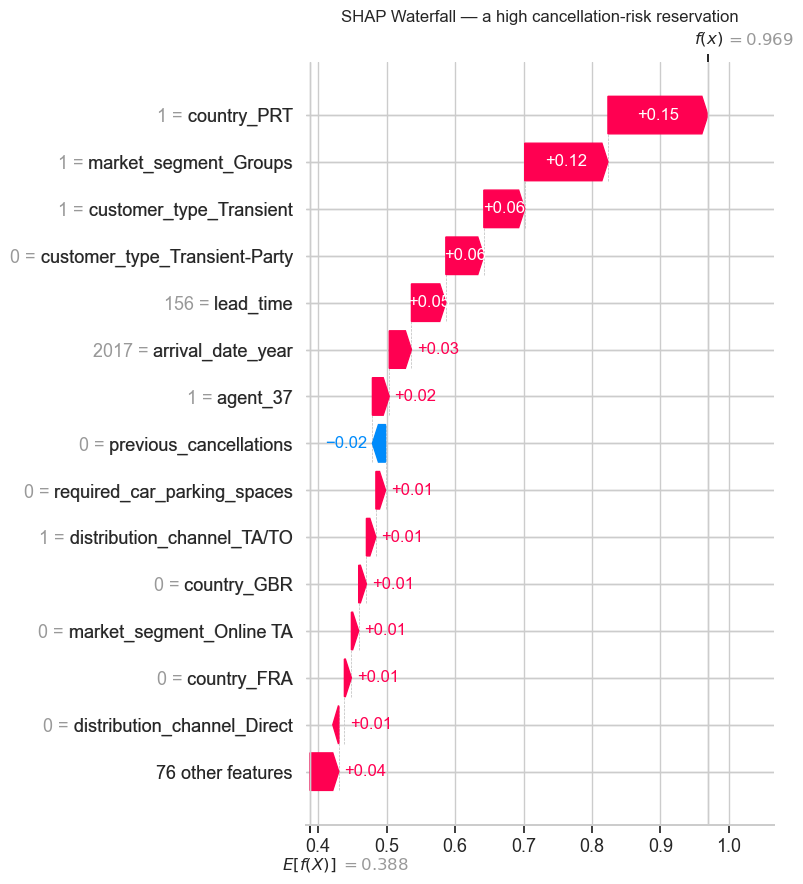

,Feature,Feature_Value,SHAP_Value,Abs_SHAP,Direction
74,country_PRT,1.0,0.146086,0.146086,キャンセル予測を押し上げる
36,market_segment_Groups,1.0,0.121623,0.121623,キャンセル予測を押し上げる
57,customer_type_Transient,1.0,0.059724,0.059724,キャンセル予測を押し上げる
58,customer_type_Transient-Party,0.0,0.055526,0.055526,キャンセル予測を押し上げる
0,lead_time,156.0,0.050263,0.050263,キャンセル予測を押し上げる
1,arrival_date_year,2017.0,0.032404,0.032404,キャンセル予測を押し上げる
83,agent_37,1.0,0.024637,0.024637,キャンセル予測を押し上げる
10,previous_cancellations,0.0,-0.019261,0.019261,キャンセル予測を押し下げる
12,required_car_parking_spaces,0.0,0.014159,0.014159,キャンセル予測を押し上げる
43,distribution_channel_TA/TO,1.0,0.013840,0.013840,キャンセル予測を押し上げる


In [12]:
# SHAPサンプル内でキャンセル確率が最も高い予約を選ぶ
high_risk_position = int(np.argmax(shap_model_probability))
high_risk_index = shap_validation_index[high_risk_position]
high_risk_probability = float(shap_model_probability[high_risk_position])
high_risk_prediction = int(high_risk_probability >= FINAL_THRESHOLD)
high_risk_actual = int(y_shap_validation.loc[high_risk_index])

print("対象行の元DataFrame index:", high_risk_index)
print(f"キャンセル予測確率: {high_risk_probability:.4f}")
print(f"閾値{FINAL_THRESHOLD:.2f}での予測クラス: {high_risk_prediction}")
print("実際のクラス:", high_risk_actual)
print(f"SHAP基準値: {class_1_base_values[high_risk_position]:.4f}")

shap.plots.waterfall(
    class_1_explanation[high_risk_position],
    max_display=15,
    show=False,
)
plt.title("SHAP Waterfall — a high cancellation-risk reservation")
plt.tight_layout()
plt.show()

# Waterfall対象予約で寄与の絶対値が大きい特徴量を表にする
waterfall_contributions = (
    pd.DataFrame({
        "Feature": shap_feature_names,
        "Feature_Value": X_shap_matrix[high_risk_position],
        "SHAP_Value": class_1_shap_values[high_risk_position],
    })
    .assign(
        Abs_SHAP=lambda frame: frame["SHAP_Value"].abs(),
        Direction=lambda frame: np.where(
            frame["SHAP_Value"] > 0,
            "キャンセル予測を押し上げる",
            "キャンセル予測を押し下げる",
        ),
    )
    .sort_values("Abs_SHAP", ascending=False)
)
display(waterfall_contributions.head(15).round(6))


## 7. SHAP分析の考察

Beeswarmの読み取りを補助するため、重要度上位20列について寄与の方向を集計する。数値特徴量は中央値より高い群、One-Hot列は該当時（値=1）の平均SHAP値を使う。

これは非線形モデルの局所効果を単純化した補助集計であり、すべての予約で同じ方向に働くことを意味しない。Summary PlotとWaterfall Plotも合わせて確認する。


In [13]:
direction_rows = []
for feature_name in shap_individual_importance.head(20)["Feature"]:
    feature_position = shap_feature_names.index(feature_name)
    feature_values = X_shap_matrix[:, feature_position]
    feature_shap = class_1_shap_values[:, feature_position]
    unique_values = np.unique(feature_values)

    if np.all(np.isin(unique_values, [0, 1])):
        active_mask = feature_values == 1
        active_mean = (
            float(feature_shap[active_mask].mean())
            if active_mask.any()
            else np.nan
        )
        direction_rows.append({
            "Feature": feature_name,
            "Comparison": "One-Hot該当時（値=1）の平均",
            "Mean_SHAP": active_mean,
            "Direction": (
                "判定不可"
                if np.isnan(active_mean)
                else ("押し上げ傾向" if active_mean > 0 else "押し下げ傾向")
            ),
            "Group_Size": int(active_mask.sum()),
        })
    else:
        median_value = float(np.median(feature_values))
        high_mask = feature_values > median_value
        high_mean = (
            float(feature_shap[high_mask].mean())
            if high_mask.any()
            else np.nan
        )
        direction_rows.append({
            "Feature": feature_name,
            "Comparison": f"中央値({median_value:.3g})より高い群の平均",
            "Mean_SHAP": high_mean,
            "Direction": (
                "判定不可"
                if np.isnan(high_mean)
                else ("押し上げ傾向" if high_mean > 0 else "押し下げ傾向")
            ),
            "Group_Size": int(high_mask.sum()),
        })

shap_direction_summary = pd.DataFrame(direction_rows)
display(shap_direction_summary.round(6))


,Feature,Comparison,Mean_SHAP,Direction,Group_Size
0,country_PRT,One-Hot該当時（値=1）の平均,0.128917,押し上げ傾向,194
1,lead_time,中央値(61)より高い群の平均,0.040855,押し上げ傾向,297
2,customer_type_Transient,One-Hot該当時（値=1）の平均,0.028559,押し上げ傾向,505
3,market_segment_Groups,One-Hot該当時（値=1）の平均,0.098542,押し上げ傾向,89
4,arrival_date_year,中央値(2.02e+03)より高い群の平均,NaN,判定不可,0
5,previous_cancellations,中央値(0)より高い群の平均,0.206678,押し上げ傾向,3
6,agent_9,One-Hot該当時（値=1）の平均,0.030087,押し上げ傾向,189
7,customer_type_Transient-Party,One-Hot該当時（値=1）の平均,-0.048790,押し下げ傾向,88
8,required_car_parking_spaces,中央値(0)より高い群の平均,-0.165204,押し下げ傾向,37
9,agent_Other,One-Hot該当時（値=1）の平均,-0.019536,押し下げ傾向,165


In [14]:
valid_directions = shap_direction_summary.dropna(subset=["Mean_SHAP"])
push_up_features = (
    valid_directions[valid_directions["Mean_SHAP"] > 0]
    .sort_values("Mean_SHAP", ascending=False)
    .head(5)["Feature"]
    .tolist()
)
push_down_features = (
    valid_directions[valid_directions["Mean_SHAP"] < 0]
    .sort_values("Mean_SHAP")
    .head(5)["Feature"]
    .tolist()
)

display(Markdown(f"""
### 寄与方向の補助集計から読み取れること

- キャンセル予測を押し上げる傾向が見られた例：{', '.join(f'`{name}`' for name in push_up_features) or '該当なし'}
- キャンセル予測を押し下げる傾向が見られた例：{', '.join(f'`{name}`' for name in push_down_features) or '該当なし'}

この結果はValidationサンプル内の平均的な傾向である。特徴量同士の組み合わせによって寄与方向が変わる可能性があるため、因果関係としては解釈しない。
"""))



### 寄与方向の補助集計から読み取れること

- キャンセル予測を押し上げる傾向が見られた例：`previous_cancellations`, `country_PRT`, `market_segment_Groups`, `lead_time`, `agent_9`
- キャンセル予測を押し下げる傾向が見られた例：`required_car_parking_spaces`, `agent_7`, `country_FRA`, `customer_type_Transient-Party`, `country_DEU`

この結果はValidationサンプル内の平均的な傾向である。特徴量同士の組み合わせによって寄与方向が変わる可能性があるため、因果関係としては解釈しない。


## 8. 分析結果のまとめ・ビジネスへの示唆

以下では、実行結果から重要な元特徴量、寄与方向、`country`と`agent`の順位を自動で整理する。施策案はモデルの予測を活用する方法であり、SHAPだけからキャンセル原因を断定するものではない。


In [15]:
top10_grouped = shap_grouped_importance.head(10)
top10_lines = "\n".join(
    f"{rank}. `{row.Original_Feature}`: {row.Mean_Abs_SHAP:.4f}"
    for rank, row in top10_grouped.iterrows()
)

def grouped_feature_text(feature_name):
    matched = shap_grouped_importance[
        shap_grouped_importance["Original_Feature"] == feature_name
    ]
    if matched.empty:
        return f"`{feature_name}`は集約表にありません"
    rank = int(matched.index[0])
    value = float(matched.iloc[0]["Mean_Abs_SHAP"])
    return f"`{feature_name}`は集約{rank}位（{value:.4f}）"

country_text = grouped_feature_text(COUNTRY)
agent_text = grouped_feature_text("agent")

display(Markdown(f"""
### 重要な元特徴量 上位10個

{top10_lines}

### キャンセル予測への寄与

- 押し上げる傾向が見られた例：{', '.join(f'`{name}`' for name in push_up_features) or '該当なし'}
- 押し下げる傾向が見られた例：{', '.join(f'`{name}`' for name in push_down_features) or '該当なし'}
- {country_text}
- {agent_text}

### ホテルのキャンセル対策への活用

- 閾値{FINAL_THRESHOLD:.2f}で高リスクと判定された予約を、確認メールや予約内容の再確認などの優先対象にする。
- 重要な予約属性や販売チャネルごとに、連絡時期や対応方法を検証する。
- 国や代理店の情報だけを理由に不利益な扱いをせず、誤検知や公平性にも注意する。
- 導入後はキャンセル率だけでなく、対応件数、顧客体験、施策コストも将来期間で検証する。

### 分析の限界

- SHAP値はモデルの予測への寄与であり、キャンセルの因果関係ではない。
- 相関する特徴量の間では寄与が分散し、重要度順位が変わることがある。
- 今回はValidationから抽出した{shap_sample_size}件の説明であり、期間や母集団が変わると結果も変わり得る。
- SHAP分析用モデルはTrainのみで学習しており、02のTrain＋Validationで再学習したFinal Test用モデルとは学習範囲が異なる。
- SHAP値の単位は **{shap_output_unit}**。`predict_proba`との最大再構成誤差は `{shap_additivity_max_error:.2e}` だった。
"""))



### 重要な元特徴量 上位10個

1. `country`: 0.1473
2. `agent`: 0.0662
3. `customer_type`: 0.0604
4. `market_segment`: 0.0559
5. `lead_time`: 0.0539
6. `arrival_date_year`: 0.0316
7. `previous_cancellations`: 0.0267
8. `required_car_parking_spaces`: 0.0222
9. `distribution_channel`: 0.0175
10. `hotel`: 0.0156

### キャンセル予測への寄与

- 押し上げる傾向が見られた例：`previous_cancellations`, `country_PRT`, `market_segment_Groups`, `lead_time`, `agent_9`
- 押し下げる傾向が見られた例：`required_car_parking_spaces`, `agent_7`, `country_FRA`, `customer_type_Transient-Party`, `country_DEU`
- `country`は集約1位（0.1473）
- `agent`は集約2位（0.0662）

### ホテルのキャンセル対策への活用

- 閾値0.30で高リスクと判定された予約を、確認メールや予約内容の再確認などの優先対象にする。
- 重要な予約属性や販売チャネルごとに、連絡時期や対応方法を検証する。
- 国や代理店の情報だけを理由に不利益な扱いをせず、誤検知や公平性にも注意する。
- 導入後はキャンセル率だけでなく、対応件数、顧客体験、施策コストも将来期間で検証する。

### 分析の限界

- SHAP値はモデルの予測への寄与であり、キャンセルの因果関係ではない。
- 相関する特徴量の間では寄与が分散し、重要度順位が変わることがある。
- 今回はValidationから抽出した600件の説明であり、期間や母集団が変わると結果も変わり得る。
- SHAP分析用モデルはTrainのみで学習しており、02のTrain＋Validationで再学習したFinal Test用モデルとは学習範囲が異なる。
- SHAP値の単位は **キャンセル確率（predict_probaの確率単位）**。`predict_proba`との最大再構成誤差は `6.31e-15` だった。
